In [1]:
# ============================================================
# [CELL 1] MOUNT GOOGLE DRIVE
# ============================================================
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [2]:
# ============================================================
# [CELL 2] SETUP - Cai dat thu vien can thiet
# ------------------------------------------------------------
# pandas: doc file tracks_final.csv
# opencv: doc video, ve vach ao va bbox de kiem tra truc quan
# matplotlib: hien thi anh ngay trong Colab de kiem tra vach
# ============================================================
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
print("Da import xong thu vien.")


Da import xong thu vien.


In [3]:
# ============================================================
# [CELL 3] PATH - Khai bao duong dan file du lieu quy dao
# ------------------------------------------------------------
# FINAL_CSV: file da qua xu ly majority voting o muc 3.4.1,
#            moi track_id chi con dung 1 nhan lop duy nhat.
# VIDEO_OUT: video co ve ID, dung de trich khung hinh mau
#            phuc vu kiem tra vi tri vach cat truoc khi dem.
# ============================================================
import os

OUT_DIR    = "/content/drive/MyDrive/Do an AI giao thong/Tracking-LineCrossing"
FINAL_CSV  = os.path.join(OUT_DIR, "tracks_final.csv")
VIDEO_OUT  = os.path.join(OUT_DIR, "tracked_output.mp4")

assert os.path.exists(FINAL_CSV), f"Khong thay file: {FINAL_CSV}"
assert os.path.exists(VIDEO_OUT), f"Khong thay video: {VIDEO_OUT}"

df = pd.read_csv(FINAL_CSV)
print("Da doc du lieu quy dao. Tong so dong:", len(df))
print("Tong so ma dinh danh:", df['track_id'].nunique())
print("Cac cot du lieu:", list(df.columns))


Da doc du lieu quy dao. Tong so dong: 865
Tong so ma dinh danh: 15
Cac cot du lieu: ['frame', 'track_id', 'class', 'cx', 'cy', 'x1', 'y1', 'x2', 'y2', 'class_final']


Kich thuoc khung hinh: rong=634, cao=374


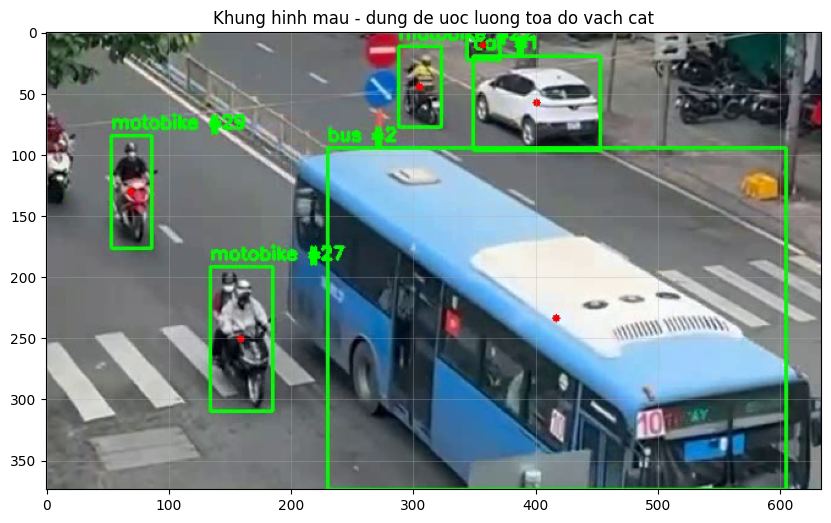

In [4]:
# ============================================================
# [CELL 4] TRICH 1 KHUNG HINH MAU - De xac dinh vi tri vach cat
# ------------------------------------------------------------
# Lay 1 frame giua video de lam nen, giup anh nhin ro duong,
# tu do uoc luong toa do 2 diem dau-cuoi cua vach ao can dat.
# ============================================================
cap = cv2.VideoCapture(VIDEO_OUT)
tong_so_frame = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.set(cv2.CAP_PROP_POS_FRAMES, tong_so_frame // 2)
ok, khung_mau = cap.read()
cap.release()

assert ok, "Khong doc duoc khung hinh mau tu video."

khung_mau_rgb = cv2.cvtColor(khung_mau, cv2.COLOR_BGR2RGB)
H, W = khung_mau.shape[:2]
print(f"Kich thuoc khung hinh: rong={W}, cao={H}")

plt.figure(figsize=(10, 6))
plt.imshow(khung_mau_rgb)
plt.title("Khung hinh mau - dung de uoc luong toa do vach cat")
plt.axis('on')
plt.grid(True, alpha=0.3)
plt.show()


In [5]:
# ============================================================
# [CELL 5] KHAI BAO VACH CAT - Toa do lay truc tiep tu anh mau
# ------------------------------------------------------------
# Toa do duoc doc truc tiep tren Hinh khung hinh mau da xuat o
# Cell 4, ung voi vi tri duong mau do mong muon dat lam vach cat.
# ============================================================

VACH_X1, VACH_Y1 = 5, 250
VACH_X2, VACH_Y2 = 630, 180
print(f"Vach cat: tu ({VACH_X1},{VACH_Y1}) den ({VACH_X2},{VACH_Y2})")


Vach cat: tu (5,250) den (630,180)


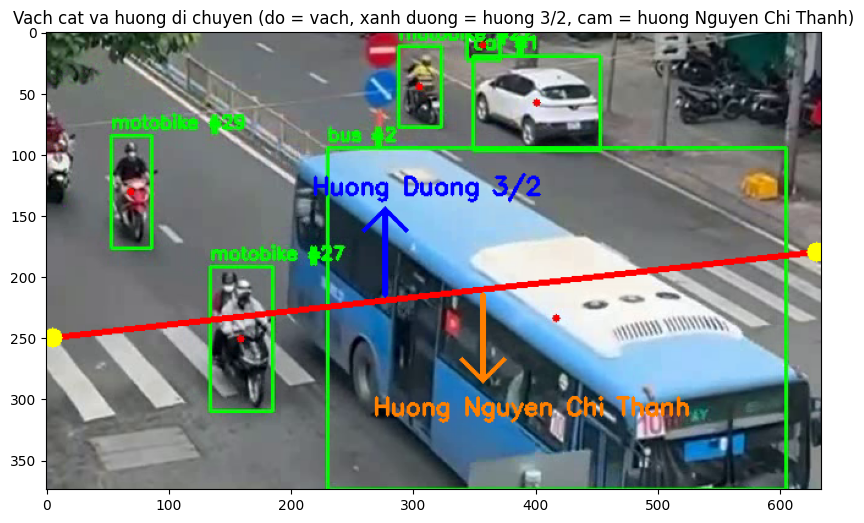

Da luu anh: /content/hinh_3_4_vach_cat_huong.jpg
Anh nay co the dung truc tiep lam Hinh 3.4 trong bao cao, khong can chinh sua them.


In [6]:
# ============================================================
# [CELL 6] KIEM TRA TRUC QUAN VACH CAT DA KHAI BAO
#          (co bo sung mui ten chi huong 2 con duong)
# ------------------------------------------------------------
# Ve vach mau do de len khung hinh mau, giup anh xac nhan
# vach da nam dung vi tri mong muon truoc khi chay chinh thuc.
# Bo sung: ve them 2 mui ten chi huong ngay tren hinh, kem
# nhan chu ten duong, dung lam Hinh 3.4 trong bao cao (khong
# can chinh sua them bang phan mem ngoai).
#   - Mui ten huong LEN  = huong di ra Duong 3 Thang 2
#   - Mui ten huong XUONG = huong di ra Duong Nguyen Chi Thanh
# Neu chua dung vi tri mong muon, quay lai Cell 5 sua toa do
# roi chay lai Cell 6 nay.
# ============================================================
anh_kiem_tra = khung_mau.copy()

# --- Ve vach cat (giu nguyen nhu ban goc) ---
cv2.line(anh_kiem_tra, (VACH_X1, VACH_Y1), (VACH_X2, VACH_Y2), (0, 0, 255), 3)
cv2.circle(anh_kiem_tra, (VACH_X1, VACH_Y1), 8, (0, 255, 255), -1)
cv2.circle(anh_kiem_tra, (VACH_X2, VACH_Y2), 8, (0, 255, 255), -1)

# --- Xac dinh diem giua vach lam goc dat mui ten ---
diem_giua_x = (VACH_X1 + VACH_X2) // 2
diem_giua_y = (VACH_Y1 + VACH_Y2) // 2

DO_DAI_MUI_TEN = 70   # dieu chinh do dai mui ten neu can

# --- Mui ten huong LEN: chi huong Duong 3 Thang 2 ---
diem_dau_len   = (diem_giua_x - 40, diem_giua_y)
diem_cuoi_len  = (diem_giua_x - 40, diem_giua_y - DO_DAI_MUI_TEN)
cv2.arrowedLine(anh_kiem_tra, diem_dau_len, diem_cuoi_len,
                (255, 0, 0), 4, tipLength=0.35)
cv2.putText(anh_kiem_tra, "Huong Duong 3/2",
            (diem_cuoi_len[0] - 60, diem_cuoi_len[1] - 12),
            cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255, 0, 0), 2)

# --- Mui ten huong XUONG: chi huong Duong Nguyen Chi Thanh ---
diem_dau_xuong  = (diem_giua_x + 40, diem_giua_y)
diem_cuoi_xuong = (diem_giua_x + 40, diem_giua_y + DO_DAI_MUI_TEN)
cv2.arrowedLine(anh_kiem_tra, diem_dau_xuong, diem_cuoi_xuong,
                (0, 128, 255), 4, tipLength=0.35)
cv2.putText(anh_kiem_tra, "Huong Nguyen Chi Thanh",
            (diem_cuoi_xuong[0] - 90, diem_cuoi_xuong[1] + 28),
            cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 128, 255), 2)

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(anh_kiem_tra, cv2.COLOR_BGR2RGB))
plt.title("Vach cat va huong di chuyen (do = vach, xanh duong = huong 3/2, cam = huong Nguyen Chi Thanh)")
plt.axis('on')
plt.show()

# --- Luu rieng ra file de dung truc tiep lam Hinh 3.4 trong bao cao ---
cv2.imwrite("/content/hinh_3_4_vach_cat_huong.jpg", anh_kiem_tra)
print("Da luu anh: /content/hinh_3_4_vach_cat_huong.jpg")
print("Anh nay co the dung truc tiep lam Hinh 3.4 trong bao cao, khong can chinh sua them.")

In [7]:
# ============================================================
# [CELL 7] LOGIC DEM LINE-CROSSING - Xac dinh su kien cat vach
#          VA DOI TEN CHIEU THEO DUNG TEN DUONG THUC TE
# ------------------------------------------------------------
# Nguyen ly xac dinh su kien cat vach:
#   - Vach cat duoc bieu dien boi vector tu diem (VACH_X1,VACH_Y1)
#     den diem (VACH_X2,VACH_Y2).
#   - Voi moi diem P (tam bbox), tinh tich co huong giua vector
#     vach va vector tu diem dau vach den P. Dau cua tich co
#     huong cho biet P dang o phia nao cua vach (duong/am).
#   - Voi moi track_id, duyet qua cac khung hinh theo thu tu
#     thoi gian. Neu dau tich co huong doi chieu giua 2 khung
#     hinh lien tiep => phuong tien da cat qua vach tai thoi
#     diem do. Chi ghi nhan 1 lan duy nhat cho moi track_id.
#
# Vach cat chinh thuc da chot: tu (5,250) den (630,180)
#   - Chieu 1 (phia duoi -> phia tren vach) = huong di ra
#     Duong 3 Thang 2
#   - Chieu 2 (phia tren -> phia duoi vach) = huong di ra
#     Duong Nguyen Chi Thanh
#
# Cell nay da gop chung buoc doi ten chieu (truoc day tach
# rieng thanh Cell 7B) ngay vao cuoi, de moi lan chay lai Cell
# nay deu tu dong tinh toan lai tu du lieu goc va doi ten dung
# 1 lan, tranh loi NaN do lo chay lai buoc doi ten nhieu lan
# tren du lieu da duoc doi ten tu truoc.
#
# [CAP NHAT] Bo sung cot "timestamp" cho tung su kien, tinh
# bang cach lay mot moc thoi gian goc (THOI_GIAN_BAT_DAU - thoi
# diem he thong bat dau chay chuong trinh demo) cong them do
# lech giay tuong ung voi so frame ma phuong tien cat vach,
# dua tren FPS cua video. Nho vay timestamp cua tung xe se trai
# deu theo dung tien trinh video thay vi trung nhau toan bo.
#
# LUU Y: Cell nay tu dong do bien FPS trong notebook (FPS, fps
# hoac video_fps). Neu khong tim thay bien nao, se dung mac
# dinh 30 va in canh bao - ban nen kiem tra lai va sua ten bien
# cho khop voi notebook cua minh neu can.
# ============================================================

from datetime import datetime, timedelta
from zoneinfo import ZoneInfo
import datetime as dt

# --- Tu dong do bien FPS dang co san trong notebook ---
if "FPS" in dir():
    _FPS_DEM = FPS
elif "fps" in dir():
    _FPS_DEM = fps
elif "video_fps" in dir():
    _FPS_DEM = video_fps
else:
    _FPS_DEM = 30
    print("[CANH BAO] Khong tim thay bien FPS/fps/video_fps trong notebook.")
    print("Dang dung gia tri mac dinh 30 FPS. Neu video cua ban co FPS khac,")
    print("hay gan lai bien FPS truoc khi chay Cell nay, vi du: FPS = 25")

print(f"Dang su dung FPS = {_FPS_DEM} de tinh timestamp cho tung su kien.")
print()

# Moc thoi gian goc cua lan chay demo nay, theo GIO VIET NAM
# (Asia/Ho_Chi_Minh, UTC+7), tranh truong hop Colab chay server
# theo gio UTC lam lech 7 tieng so voi gio thuc te.
THOI_GIAN_BAT_DAU = dt.datetime.now(ZoneInfo("Asia/Ho_Chi_Minh"))


def tinh_phia_diem(px, py, x1, y1, x2, y2):
    """Tinh tich co huong, dau duong/am the hien phia cua diem
    (px,py) so voi duong thang di qua (x1,y1) va (x2,y2)."""
    return (x2 - x1) * (py - y1) - (y2 - y1) * (px - x1)


ket_qua_dem = []
da_dem = set()  # luu track_id da duoc dem, tranh dem trung

# Sap xep du lieu theo track_id roi theo frame de duyet dung thu tu
df_sap_xep = df.sort_values(["track_id", "frame"]).reset_index(drop=True)

for track_id, nhom in df_sap_xep.groupby("track_id"):
    nhom = nhom.reset_index(drop=True)
    lop = nhom.loc[0, "class_final"] if "class_final" in nhom.columns else nhom.loc[0, "class"]

    phia_truoc = None
    for i in range(len(nhom)):
        cx, cy = nhom.loc[i, "cx"], nhom.loc[i, "cy"]
        phia_hien_tai = tinh_phia_diem(cx, cy, VACH_X1, VACH_Y1, VACH_X2, VACH_Y2)

        if phia_truoc is not None and track_id not in da_dem:
            frame_hien_tai = nhom.loc[i, "frame"]
            thoi_gian_su_kien = (
                THOI_GIAN_BAT_DAU + timedelta(seconds=frame_hien_tai / _FPS_DEM)
            ).strftime("%Y-%m-%d %H:%M:%S")

            # Kiem tra doi dau (1 duong 1 am) => da cat qua vach
            if phia_truoc > 0 and phia_hien_tai < 0:
                chieu = "Chieu 1"
                ket_qua_dem.append({
                    "timestamp": thoi_gian_su_kien,
                    "track_id": track_id, "class": lop, "chieu": chieu,
                    "frame_cat_vach": frame_hien_tai,
                })
                da_dem.add(track_id)
            elif phia_truoc < 0 and phia_hien_tai > 0:
                chieu = "Chieu 2"
                ket_qua_dem.append({
                    "timestamp": thoi_gian_su_kien,
                    "track_id": track_id, "class": lop, "chieu": chieu,
                    "frame_cat_vach": frame_hien_tai,
                })
                da_dem.add(track_id)

        phia_truoc = phia_hien_tai

ket_qua_dem = pd.DataFrame(ket_qua_dem)

print(f"Tong so luot phuong tien cat qua vach: {len(ket_qua_dem)}")
print(f"(tren tong so {df['track_id'].nunique()} ma dinh danh co trong du lieu)")
print()

# --- Doi ten Chieu 1 / Chieu 2 thanh ten duong thuc te ---
ANH_XA_TEN_CHIEU = {
    "Chieu 1": "Huong di Duong 3 Thang 2",
    "Chieu 2": "Huong di Duong Nguyen Chi Thanh",
}

if len(ket_qua_dem) > 0:
    ket_qua_dem["chieu"] = ket_qua_dem["chieu"].map(ANH_XA_TEN_CHIEU)
    print(ket_qua_dem.to_string(index=False))
else:
    print("Khong co luot cat vach nao duoc ghi nhan.")

[CANH BAO] Khong tim thay bien FPS/fps/video_fps trong notebook.
Dang dung gia tri mac dinh 30 FPS. Neu video cua ban co FPS khac,
hay gan lai bien FPS truoc khi chay Cell nay, vi du: FPS = 25
Dang su dung FPS = 30 de tinh timestamp cho tung su kien.

Tong so luot phuong tien cat qua vach: 6
(tren tong so 15 ma dinh danh co trong du lieu)

          timestamp  track_id    class                           chieu  frame_cat_vach
2026-09-01 09:58:55         2      bus Huong di Duong Nguyen Chi Thanh              60
2026-09-01 09:58:54        22 motobike        Huong di Duong 3 Thang 2              24
2026-09-01 09:58:56        27 motobike Huong di Duong Nguyen Chi Thanh              72
2026-09-01 09:58:57        29 motobike Huong di Duong Nguyen Chi Thanh              96
2026-09-01 09:58:57        35 motobike Huong di Duong Nguyen Chi Thanh             117
2026-09-01 09:58:58        41 motobike Huong di Duong Nguyen Chi Thanh             134


In [8]:
# ============================================================
# [CELL 8] THONG KE KET QUA DEM - Theo loai phuong tien va chieu
# ------------------------------------------------------------
# Tong hop so luot dem duoc, chia theo loai phuong tien va
# theo tung chieu di chuyen, phuc vu doi chieu voi so dem thu
# cong (thu cong) khi danh gia do chinh xac o Chuong 4.
#
# [CAP NHAT] Ngoai file tong hop "ket_qua_dem_line_crossing.csv"
# dung cho Chuong 4, cell nay con xuat them file chi tiet
# "vehicle_events.csv" (moi dong la mot su kien 1 phuong tien
# cat vach, kem timestamp) de lam nguon du lieu dau vao cho
# SQLite va Flask Dashboard o muc 3.5.
# ============================================================

if len(ket_qua_dem) > 0:
    print("Tong so luot theo tung loai phuong tien:")
    print(ket_qua_dem["class"].value_counts())
    print()
    print("Tong so luot theo tung chieu di chuyen:")
    print(ket_qua_dem["chieu"].value_counts())
    print()
    print("Bang cheo: loai phuong tien x chieu di chuyen")
    print(pd.crosstab(ket_qua_dem["class"], ket_qua_dem["chieu"]))

    # --------------------------------------------------------
    # File tong hop, dung lam so lieu cho Chuong 4
    # --------------------------------------------------------
    KET_QUA_CSV = os.path.join(OUT_DIR, "ket_qua_dem_line_crossing.csv")
    ket_qua_dem.to_csv(KET_QUA_CSV, index=False)
    print(f"\nDa luu ket qua dem tai: {KET_QUA_CSV}")

    # --------------------------------------------------------
    # File chi tiet tung su kien, dung lam nguon nap vao SQLite
    # --------------------------------------------------------
    EVENT_CSV = os.path.join(OUT_DIR, "vehicle_events.csv")
    ket_qua_dem[
        ["timestamp", "track_id", "class", "chieu", "frame_cat_vach"]
    ].to_csv(
        EVENT_CSV,
        index=False,
        encoding="utf-8-sig"
    )
    print(f"Da luu danh sach su kien (co timestamp) tai: {EVENT_CSV}")

else:
    print("Khong co du lieu de thong ke. Kiem tra lai vi tri vach cat o Cell 5.")

Tong so luot theo tung loai phuong tien:
class
motobike    5
bus         1
Name: count, dtype: int64

Tong so luot theo tung chieu di chuyen:
chieu
Huong di Duong Nguyen Chi Thanh    5
Huong di Duong 3 Thang 2           1
Name: count, dtype: int64

Bang cheo: loai phuong tien x chieu di chuyen
chieu     Huong di Duong 3 Thang 2  Huong di Duong Nguyen Chi Thanh
class                                                              
bus                              0                                1
motobike                         1                                4

Da luu ket qua dem tai: /content/drive/MyDrive/Do an AI giao thong/Tracking-LineCrossing/ket_qua_dem_line_crossing.csv
Da luu danh sach su kien (co timestamp) tai: /content/drive/MyDrive/Do an AI giao thong/Tracking-LineCrossing/vehicle_events.csv


In [9]:
# ============================================================
# [CELL 9] XUAT VIDEO CO VE VACH VA SO DEM REAL-TIME
# ------------------------------------------------------------
# Ve lai toan bo video, lan nay co them: duong vach mau do co
# dinh, va bo dem hien thi goc tren cung ben trai, tang dan
# moi khi co 1 phuong tien cat qua vach. Video nay dung de
# minh hoa truc quan cho Hinh minh hoa o muc 3.4.2 hoac Chuong 4.
# ============================================================
cap = cv2.VideoCapture(VIDEO_OUT)
Wv = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
Hv = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
FPS = cap.get(cv2.CAP_PROP_FPS) or 25

VIDEO_DEM = os.path.join(OUT_DIR, "video_dem_line_crossing.mp4")
writer = cv2.VideoWriter(VIDEO_DEM, cv2.VideoWriter_fourcc(*'mp4v'), FPS, (Wv, Hv))

# Tra cuu nhanh: frame nao co su kien cat vach, cua track_id nao
frame_co_su_kien = {}
if len(ket_qua_dem) > 0:
    for _, hang in ket_qua_dem.iterrows():
        frame_co_su_kien.setdefault(int(hang["frame_cat_vach"]), []).append(int(hang["track_id"]))

so_dem_hien_tai = 0
frame_idx = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break

    # Ve vach cat co dinh
    cv2.line(frame, (VACH_X1, VACH_Y1), (VACH_X2, VACH_Y2), (0, 0, 255), 3)

    if frame_idx in frame_co_su_kien:
        so_dem_hien_tai += len(frame_co_su_kien[frame_idx])

    cv2.putText(frame, f"So xe da dem: {so_dem_hien_tai}", (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 2)

    writer.write(frame)
    frame_idx += 1

cap.release()
writer.release()
print(f"Da xuat video dem: {VIDEO_DEM}")
print(f"Tong so xe da dem trong toan bo video: {so_dem_hien_tai}")


Da xuat video dem: /content/drive/MyDrive/Do an AI giao thong/Tracking-LineCrossing/video_dem_line_crossing.mp4
Tong so xe da dem trong toan bo video: 6
